# Consolidação dos Resultados — Previsão de Precipitação Diária

## 1. Objetivo

Este notebook tem como objetivo consolidar os resultados obtidos nas etapas de coleta, pré-processamento, análise exploratória, modelagem e avaliação de modelos de aprendizado de máquina para previsão da precipitação diária na estação meteorológica A701 — Mirante de Santana, localizada em São Paulo (SP).

O estudo utiliza dados meteorológicos do Instituto Nacional de Meteorologia (INMET), referentes ao período de 2010 a 2025.

A consolidação busca organizar as principais métricas, tabelas e visualizações para apoiar a elaboração do relatório final do Trabalho de Conclusão de Curso (TCC) da UNIVESP.

Os resultados serão apresentados considerando:

- Características e qualidade da base de dados.
- Desempenho dos modelos na validação temporal.
- Avaliação do modelo selecionado no conjunto de teste.
- Análise dos erros de previsão por intensidade de precipitação.
- Resultados da abordagem complementar de classificação e regressão em duas etapas.

A interpretação priorizará a distinção entre os resultados de validação e de teste, bem como as limitações dos modelos na previsão de eventos de precipitação intensa.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Carregamento da base diária
caminho_dados = "../data/gold/a701_2010_2025_diario_horario_sp.parquet"

df = pd.read_parquet(caminho_dados)

# Conversão da coluna de data
df["DATA (YYYY-MM-DD)"] = pd.to_datetime(
    df["DATA (YYYY-MM-DD)"]
)

# Informações iniciais
print(f"Total de registros: {len(df):,}")

print(
    "Período:",
    df["DATA (YYYY-MM-DD)"].min().date(),
    "até",
    df["DATA (YYYY-MM-DD)"].max().date()
)

print(
    "Dias com precipitação válida:",
    df["precipitacao_diaria_mm"].notna().sum()
)

print(
    "Dias sem precipitação válida:",
    df["precipitacao_diaria_mm"].isna().sum()
)

display(df.head())

Total de registros: 5,844
Período: 2010-01-01 até 2025-12-31
Dias com precipitação válida: 5652
Dias sem precipitação válida: 192


,DATA (YYYY-MM-DD),horas_validas,precipitacao_diaria_mm,horas_registradas,horas_esperadas,dia_completo,temperatura_media,umidade_media,pressao_media,vento_medio,temperatura_media_horas_validas,umidade_media_horas_validas,pressao_media_horas_validas,vento_medio_horas_validas
0,2010-01-01,24,6.4,24,24,True,21.212500,87.333333,923.108333,2.141667,24,24,24,24
1,2010-01-02,24,36.4,24,24,True,22.279167,84.041667,925.154167,1.179167,24,24,24,24
2,2010-01-03,24,0.4,24,24,True,24.370833,77.666667,926.783333,1.550000,24,24,24,24
3,2010-01-04,24,13.4,24,24,True,24.200000,74.416667,926.600000,1.804167,24,24,24,24
4,2010-01-05,24,50.2,24,24,True,24.641667,73.916667,923.858333,1.933333,24,24,24,24


## 2. Caracterização da precipitação diária

A caracterização da variável-alvo permite compreender a distribuição dos acumulados diários de precipitação e identificar aspectos relevantes para a modelagem preditiva.

Nesta etapa, são calculadas estatísticas descritivas, incluindo média, mediana, desvio-padrão, precipitação máxima e frequência de dias com diferentes intensidades de chuva.

Os cálculos consideram exclusivamente os dias com registros válidos de precipitação, sem substituir valores ausentes por zero.

Para a classificação dos eventos, considera-se precipitação igual ou superior a 1 mm como dia chuvoso, mantendo a definição utilizada no experimento de modelagem em duas etapas.

In [2]:
# Considera apenas registros válidos de precipitação
chuva = df["precipitacao_diaria_mm"].dropna()

total_validos = len(chuva)

indicadores = {
    "Dias válidos": total_validos,
    "Média diária (mm)": chuva.mean(),
    "Mediana diária (mm)": chuva.median(),
    "Desvio-padrão (mm)": chuva.std(),
    "Precipitação máxima (mm)": chuva.max(),
    "Dias com 0 mm": (chuva == 0).sum(),
    "Dias com chuva < 1 mm": (chuva < 1).sum(),
    "Dias com chuva >= 1 mm": (chuva >= 1).sum(),
    "Dias com chuva > 20 mm": (chuva > 20).sum(),
    "Dias com chuva > 50 mm": (chuva > 50).sum(),
}

df_indicadores = pd.DataFrame(
    indicadores.items(),
    columns=["Indicador", "Valor"]
)

display(df_indicadores.round(2))

# Frequência de dias secos e chuvosos
print(
    f"\nDias com 0 mm: "
    f"{(chuva == 0).mean() * 100:.2f}%"
)

print(
    f"Dias com chuva >= 1 mm: "
    f"{(chuva >= 1).mean() * 100:.2f}%"
)

print(
    f"Dias com chuva > 20 mm: "
    f"{(chuva > 20).mean() * 100:.2f}%"
)

print(
    f"Dias com chuva > 50 mm: "
    f"{(chuva > 50).mean() * 100:.2f}%"
)

,Indicador,Valor
0,Dias válidos,5652.00
1,Média diária (mm),4.35
2,Mediana diária (mm),0.00
3,Desvio-padrão (mm),10.88
4,Precipitação máxima (mm),142.40
5,Dias com 0 mm,3269.00
6,Dias com chuva < 1 mm,3931.00
7,Dias com chuva >= 1 mm,1721.00
8,Dias com chuva > 20 mm,404.00
9,Dias com chuva > 50 mm,63.00



Dias com 0 mm: 57.84%
Dias com chuva >= 1 mm: 30.45%
Dias com chuva > 20 mm: 7.15%
Dias com chuva > 50 mm: 1.11%


### Interpretação da distribuição da precipitação

A análise descritiva revelou uma distribuição assimétrica da precipitação diária, caracterizada pela predominância de dias secos ou com baixos acumulados.

Entre os **5.652 registros válidos**, **57,84% apresentaram precipitação igual a zero**, enquanto **30,45% registraram acumulados iguais ou superiores a 1 mm**.

A precipitação média diária foi de **4,35 mm**, com mediana de **0 mm** e desvio-padrão de **10,88 mm**. O maior acumulado diário observado foi de **142,40 mm**.

Eventos com precipitação superior a **20 mm representaram 7,15%** dos registros, enquanto eventos superiores a **50 mm corresponderam a apenas 1,11%**.

Essas características evidenciam o desafio da previsão de precipitação diária, especialmente devido à elevada frequência de valores nulos e à baixa representatividade de eventos intensos.

A predominância de dias secos também indica a necessidade de interpretar conjuntamente diferentes métricas de avaliação, uma vez que estratégias conservadoras podem apresentar baixos erros absolutos médios sem identificar adequadamente eventos chuvosos.

## 3. Comparação dos modelos na validação temporal

Foram comparadas diferentes abordagens para previsão do acumulado diário de precipitação, incluindo modelos de referência, regressão linear, Random Forest e XGBoost.

A avaliação utilizou validação cruzada temporal com cinco divisões (`TimeSeriesSplit`), aplicada exclusivamente ao conjunto de treinamento, correspondente aos primeiros 80% dos registros disponíveis para modelagem.

O desempenho foi mensurado pelas métricas de erro absoluto médio (MAE) e raiz do erro quadrático médio (RMSE), expressas em milímetros.

Essa etapa consolida os resultados obtidos no notebook de modelagem, sem realizar novos treinamentos ou utilizar o conjunto de teste final.

In [3]:

resultados_modelos = [
    {
        "Modelo": "Persistência",
        "MAE_mm": 5.910,
        "RMSE_mm": 13.212
    },
    {
        "Modelo": "Regressão Linear Temporal",
        "MAE_mm": 5.722,
        "RMSE_mm": 10.275
    },
    {
        "Modelo": "Regressão Linear Multivariada",
        "MAE_mm": 5.708,
        "RMSE_mm": 10.172
    },
    {
        "Modelo": "Random Forest Temporal",
        "MAE_mm": 6.340,
        "RMSE_mm": 10.956
    },
    {
        "Modelo": "Random Forest Multivariada",
        "MAE_mm": 5.931,
        "RMSE_mm": 10.569
    },
    {
        "Modelo": "Random Forest Otimizada",
        "MAE_mm": 5.497,
        "RMSE_mm": 10.175
    },
    {
        "Modelo": "XGBoost Inicial",
        "MAE_mm": 6.228,
        "RMSE_mm": 11.248
    },
    {
        "Modelo": "XGBoost Otimizado",
        "MAE_mm": 5.653,
        "RMSE_mm": 10.156
    }
]

df_comparacao = pd.DataFrame(resultados_modelos)

df_comparacao = df_comparacao.sort_values(
    "RMSE_mm"
).reset_index(drop=True)

display(df_comparacao.round(3))


,Modelo,MAE_mm,RMSE_mm
0,XGBoost Otimizado,5.653,10.156
1,Regressão Linear Multivariada,5.708,10.172
2,Random Forest Otimizada,5.497,10.175
3,Regressão Linear Temporal,5.722,10.275
4,Random Forest Multivariada,5.931,10.569
5,Random Forest Temporal,6.340,10.956
6,XGBoost Inicial,6.228,11.248
7,Persistência,5.910,13.212


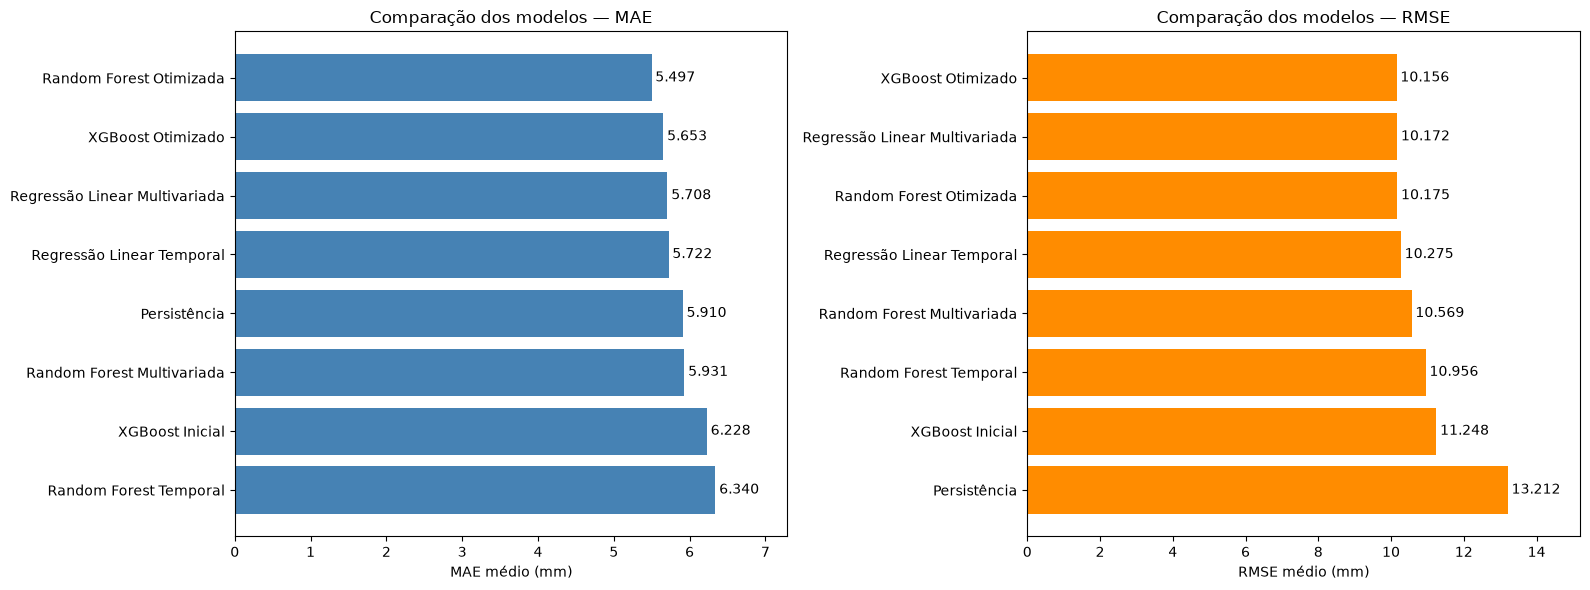

In [4]:
# Ordenação independente para cada métrica
df_mae = df_comparacao.sort_values("MAE_mm", ascending=True)
df_rmse = df_comparacao.sort_values("RMSE_mm", ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico MAE
axes[0].barh(
    df_mae["Modelo"],
    df_mae["MAE_mm"],
    color="steelblue"
)
axes[0].invert_yaxis()
axes[0].set_title("Comparação dos modelos — MAE")
axes[0].set_xlabel("MAE médio (mm)")
axes[0].set_xlim(0, df_mae["MAE_mm"].max() * 1.15)

for i, valor in enumerate(df_mae["MAE_mm"]):
    axes[0].text(valor + 0.05, i, f"{valor:.3f}", va="center")

# Gráfico RMSE
axes[1].barh(
    df_rmse["Modelo"],
    df_rmse["RMSE_mm"],
    color="darkorange"
)
axes[1].invert_yaxis()
axes[1].set_title("Comparação dos modelos — RMSE")
axes[1].set_xlabel("RMSE médio (mm)")
axes[1].set_xlim(0, df_rmse["RMSE_mm"].max() * 1.15)

for i, valor in enumerate(df_rmse["RMSE_mm"]):
    axes[1].text(valor + 0.10, i, f"{valor:.3f}", va="center")

plt.tight_layout()
plt.show()

### Análise comparativa dos modelos

A comparação dos modelos na validação temporal evidenciou que as abordagens otimizadas apresentaram os melhores resultados gerais.

A **Random Forest multivariada otimizada** obteve o menor MAE médio, de **5,497 mm**, enquanto o **XGBoost otimizado** apresentou o menor RMSE médio, de **10,156 mm**. A diferença de RMSE entre os dois modelos foi de apenas **0,019 mm**, indicando desempenho bastante próximo nesse indicador.

A **Regressão Linear Multivariada** também demonstrou desempenho competitivo, com MAE médio de **5,708 mm** e RMSE médio de **10,172 mm**, sugerindo que parte da capacidade preditiva pode ser capturada por uma abordagem de menor complexidade.

Considerando o equilíbrio entre as métricas avaliadas, especialmente o menor MAE e a proximidade do RMSE em relação ao melhor resultado observado, a **Random Forest multivariada otimizada foi selecionada como modelo principal** para avaliação no conjunto de teste.

Entretanto, as pequenas diferenças observadas entre os modelos de melhor desempenho não permitem afirmar superioridade estatística sem análises adicionais, como a avaliação da variabilidade dos erros e a aplicação de testes estatísticos apropriados.

In [6]:
# Considera apenas registros válidos de precipitação
chuva = df["precipitacao_diaria_mm"].dropna()

total_validos = len(chuva)

indicadores = {
    "Dias válidos": total_validos,
    "Média diária (mm)": chuva.mean(),
    "Mediana diária (mm)": chuva.median(),
    "Desvio-padrão (mm)": chuva.std(),
    "Precipitação máxima (mm)": chuva.max(),
    "Dias com 0 mm": (chuva == 0).sum(),
    "Dias com chuva < 1 mm": (chuva < 1).sum(),
    "Dias com chuva >= 1 mm": (chuva >= 1).sum(),
    "Dias com chuva > 20 mm": (chuva > 20).sum(),
    "Dias com chuva > 50 mm": (chuva > 50).sum(),
}

df_indicadores = pd.DataFrame(
    indicadores.items(),
    columns=["Indicador", "Valor"]
)

display(df_indicadores.round(2))

# Frequência de dias secos e chuvosos
print(
    f"\nDias com 0 mm: "
    f"{(chuva == 0).mean() * 100:.2f}%"
)

print(
    f"Dias com chuva >= 1 mm: "
    f"{(chuva >= 1).mean() * 100:.2f}%"
)

print(
    f"Dias com chuva > 20 mm: "
    f"{(chuva > 20).mean() * 100:.2f}%"
)

print(
    f"Dias com chuva > 50 mm: "
    f"{(chuva > 50).mean() * 100:.2f}%"
)

,Indicador,Valor
0,Dias válidos,5652.00
1,Média diária (mm),4.35
2,Mediana diária (mm),0.00
3,Desvio-padrão (mm),10.88
4,Precipitação máxima (mm),142.40
5,Dias com 0 mm,3269.00
6,Dias com chuva < 1 mm,3931.00
7,Dias com chuva >= 1 mm,1721.00
8,Dias com chuva > 20 mm,404.00
9,Dias com chuva > 50 mm,63.00



Dias com 0 mm: 57.84%
Dias com chuva >= 1 mm: 30.45%
Dias com chuva > 20 mm: 7.15%
Dias com chuva > 50 mm: 1.11%


## 4. Avaliação do modelo selecionado no conjunto de teste

Após a comparação dos algoritmos por validação temporal, a **Random Forest multivariada otimizada** foi selecionada para avaliação no conjunto de teste, considerando seu menor MAE médio e desempenho próximo ao melhor RMSE observado.

O modelo foi treinado com os primeiros **80% dos registros disponíveis para modelagem** e avaliado nos **20% finais**, preservando a ordem cronológica e evitando a utilização de observações posteriores no ajuste dos parâmetros.

A base de modelagem compreendeu **4.953 observações**, sendo **3.962 destinadas ao treinamento**, entre 8 de janeiro de 2010 e 11 de janeiro de 2022, e **991 reservadas para teste**, entre 12 de janeiro de 2022 e 21 de dezembro de 2025.

A avaliação final apresentou **MAE de 5,251 mm** e **RMSE de 9,217 mm**, valores inferiores às médias obtidas durante a validação temporal, de **5,497 mm** e **10,175 mm**, respectivamente.

Embora os resultados indiquem capacidade de estimar parte da variabilidade dos acumulados diários, sua interpretação deve considerar as dificuldades do modelo na previsão de eventos de precipitação elevada, investigadas nas análises seguintes.

In [8]:

df_avaliacao_final = pd.DataFrame([
    {
        "Etapa": "Validação temporal (5 folds)",
        "Modelo": "Random Forest Otimizada",
        "Observacoes_treino": 3962,
        "Observacoes_avaliadas": 3300,
        "MAE_mm": 5.497,
        "RMSE_mm": 10.175
    },
    {
        "Etapa": "Teste final",
        "Modelo": "Random Forest Otimizada",
        "Observacoes_treino": 3962,
        "Observacoes_avaliadas": 991,
        "MAE_mm": 5.251,
        "RMSE_mm": 9.217
    }
])

display(df_avaliacao_final.round(3))


,Etapa,Modelo,Observacoes_treino,Observacoes_avaliadas,MAE_mm,RMSE_mm
0,Validação temporal (5 folds),Random Forest Otimizada,3962,3300,5.497,10.175
1,Teste final,Random Forest Otimizada,3962,991,5.251,9.217


## 5. Análise dos erros por intensidade de precipitação

Para investigar as limitações do modelo selecionado, os resultados do conjunto de teste foram segmentados de acordo com a intensidade da precipitação observada.

Foram consideradas cinco faixas: precipitação nula, acima de 0 até 5 mm, acima de 5 até 20 mm, acima de 20 até 50 mm e superior a 50 mm.

Essa análise permite verificar se as métricas globais representam adequadamente o desempenho do modelo em diferentes condições meteorológicas, especialmente em eventos de precipitação intensa.

Os resultados foram obtidos a partir das previsões da Random Forest multivariada otimizada sobre o conjunto de teste final.

In [9]:

dados_erros = [
    {
        "Faixa": "0 mm",
        "Dias": 572,
        "MAE_mm": 2.85,
        "RMSE_mm": 4.03
    },
    {
        "Faixa": ">0 a 5 mm",
        "Dias": 229,
        "MAE_mm": 4.56,
        "RMSE_mm": 5.70
    },
    {
        "Faixa": ">5 a 20 mm",
        "Dias": 121,
        "MAE_mm": 5.55,
        "RMSE_mm": 6.77
    },
    {
        "Faixa": ">20 a 50 mm",
        "Dias": 59,
        "MAE_mm": 22.94,
        "RMSE_mm": 24.46
    },
    {
        "Faixa": ">50 mm",
        "Dias": 10,
        "MAE_mm": 50.68,
        "RMSE_mm": 51.59
    }
]

df_erros_faixa = pd.DataFrame(dados_erros)

df_erros_faixa["Percentual_dias"] = (
    df_erros_faixa["Dias"] /
    df_erros_faixa["Dias"].sum() * 100
)

display(df_erros_faixa.round(2))

print(
    "Total de dias avaliados:",
    df_erros_faixa["Dias"].sum()
)


,Faixa,Dias,MAE_mm,RMSE_mm,Percentual_dias
0,0 mm,572,2.85,4.03,57.72
1,>0 a 5 mm,229,4.56,5.70,23.11
2,>5 a 20 mm,121,5.55,6.77,12.21
3,>20 a 50 mm,59,22.94,24.46,5.95
4,>50 mm,10,50.68,51.59,1.01


Total de dias avaliados: 991


### Visualização dos erros por faixa de precipitação

A distribuição dos erros por faixa de precipitação foi analisada para identificar diferenças no desempenho do modelo conforme a intensidade dos eventos observados.

A visualização compara o MAE e o RMSE em cada faixa, considerando também a quantidade de registros disponíveis.

Essa análise é especialmente relevante para eventos de precipitação intensa, cuja baixa frequência pode dificultar o aprendizado dos modelos e limitar a representatividade das métricas globais.

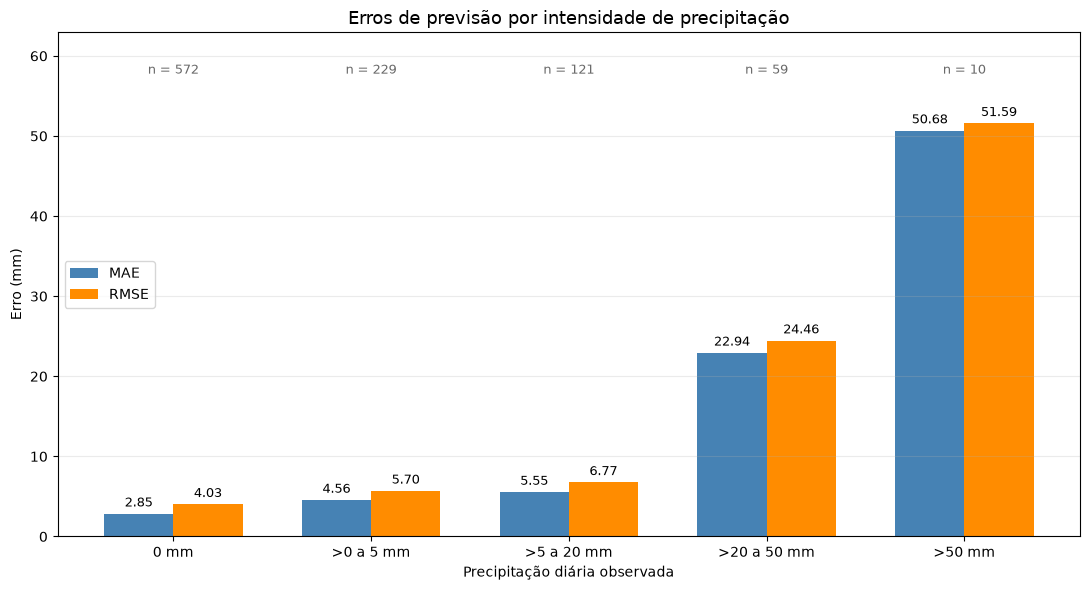

In [10]:
# Gráfico comparativo de erros por faixa
fig, ax = plt.subplots(figsize=(11, 6))

x = np.arange(len(df_erros_faixa))
largura = 0.35

barras_mae = ax.bar(
    x - largura / 2,
    df_erros_faixa["MAE_mm"],
    largura,
    label="MAE",
    color="steelblue"
)

barras_rmse = ax.bar(
    x + largura / 2,
    df_erros_faixa["RMSE_mm"],
    largura,
    label="RMSE",
    color="darkorange"
)

ax.set_title(
    "Erros de previsão por intensidade de precipitação",
    fontsize=13
)

ax.set_ylabel("Erro (mm)")
ax.set_xlabel("Precipitação diária observada")

ax.set_xticks(x)
ax.set_xticklabels(df_erros_faixa["Faixa"])

ax.legend()
ax.grid(axis="y", alpha=0.25)

# Valores de erro sobre as barras
ax.bar_label(
    barras_mae,
    fmt="%.2f",
    padding=3,
    fontsize=9
)

ax.bar_label(
    barras_rmse,
    fmt="%.2f",
    padding=3,
    fontsize=9
)

# Quantidade de dias em cada faixa
altura_maxima = df_erros_faixa["RMSE_mm"].max()

for i, dias in enumerate(df_erros_faixa["Dias"]):
    ax.text(
        i,
        altura_maxima * 1.12,
        f"n = {dias}",
        ha="center",
        fontsize=9,
        color="dimgray"
    )

ax.set_ylim(0, altura_maxima * 1.22)

plt.tight_layout()
plt.show()

### Interpretação dos erros por faixa de precipitação

A análise por faixa de intensidade mostra que o desempenho do modelo varia de forma relevante conforme o volume de chuva observado.

Nos dias sem precipitação e nos eventos de baixa a moderada intensidade, os erros permaneceram relativamente baixos, com MAE entre **2,85 mm e 5,55 mm**. Por outro lado, nos eventos mais intensos, os erros aumentaram expressivamente: na faixa acima de 20 mm e até 50 mm, o MAE foi de **22,94 mm**, enquanto nos eventos superiores a 50 mm atingiu **50,68 mm**.

Esse comportamento indica que o modelo apresenta erros menores nas situações mais frequentes da série, mas encontra maior dificuldade para representar adequadamente episódios de precipitação intensa.

Além disso, observa-se que as faixas de maior intensidade possuem menor número de ocorrências. No conjunto de teste, foram registrados **59 dias com precipitação acima de 20 mm e até 50 mm** e apenas **10 dias com acumulados superiores a 50 mm**.

A baixa frequência desses eventos pode limitar a aprendizagem de padrões associados a precipitações elevadas, contribuindo para a dificuldade de previsão. Entretanto, essa relação deve ser interpretada como uma possível explicação, e não como uma causa demonstrada pelo experimento.

Dessa forma, a análise por intensidade complementa as métricas globais, evidenciando limitações que não seriam identificadas apenas por MAE e RMSE calculados sobre todo o conjunto de teste.

### Síntese da avaliação final

A Random Forest multivariada otimizada apresentou **MAE de 5,251 mm** e **RMSE de 9,217 mm** no conjunto de teste, composto por **991 observações**, referentes ao período de 12 de janeiro de 2022 a 21 de dezembro de 2025.

A análise por intensidade de precipitação revelou diferenças importantes no comportamento das previsões. Nos dias sem chuva, o MAE foi de **2,85 mm**, enquanto nos eventos superiores a 50 mm atingiu **50,68 mm**.

Além do aumento dos erros, identificou-se uma tendência de superestimação dos baixos acumulados e subestimação dos eventos intensos. Para precipitações observadas acima de 20 mm e até 50 mm, a média prevista foi de **8,37 mm**, diante de uma média observada de **31,31 mm**. Nos eventos superiores a 50 mm, a média observada foi de **60,92 mm**, enquanto a previsão média foi de apenas **10,24 mm**.

Esses resultados indicam que o modelo consegue representar parcialmente a variabilidade da precipitação diária, mas apresenta limitações importantes na estimativa da magnitude dos eventos mais intensos.

A baixa frequência de chuvas elevadas na amostra, associada à predominância de dias secos ou com baixos acumulados, constitui uma possível explicação para esse comportamento. Destaca-se que apenas **10 observações** apresentaram precipitação superior a 50 mm no conjunto de teste, exigindo cautela na generalização dos resultados para eventos extremos.

Portanto, embora o modelo tenha apresentado desempenho competitivo na validação temporal, os resultados não sustentam seu uso isolado como ferramenta de alerta para eventos extremos, sem aperfeiçoamentos e avaliações adicionais.

## 6. Comparação com a modelagem em duas etapas

Como experimento complementar, foi investigada uma arquitetura em duas etapas para previsão da precipitação diária.

A primeira etapa utilizou um classificador Random Forest para estimar a probabilidade de ocorrência de precipitação igual ou superior a 1 mm. A segunda etapa utilizou um regressor Random Forest, treinado exclusivamente com dias chuvosos, para estimar a intensidade da precipitação.

Foram avaliados diferentes limiares de classificação (*thresholds*), entre **0,30 e 0,75**, para investigar seu impacto no erro final de previsão do acumulado diário.

Os resultados foram comparados aos da Random Forest multivariada de regressão direta otimizada e de um baseline que prevê precipitação igual a zero para todos os dias.

Todas as métricas apresentadas nesta seção correspondem à validação temporal com cinco folds, realizada sobre o conjunto de treinamento. O conjunto de teste final não foi utilizado nessa comparação complementar.

O experimento em duas etapas foi desenvolvido após a avaliação inicial do modelo direto no teste final, devendo ser interpretado como uma investigação complementar posterior à seleção original.

In [11]:

resultados_complementares = [
    {
        "Modelo": "Baseline — Sempre Zero",
        "Threshold": np.nan,
        "MAE_mm": 4.284,
        "RMSE_mm": 11.516
    },
    {
        "Modelo": "Random Forest Direta",
        "Threshold": np.nan,
        "MAE_mm": 5.497,
        "RMSE_mm": 10.175
    },
    {
        "Modelo": "Random Forest Duas Etapas",
        "Threshold": 0.30,
        "MAE_mm": 7.988,
        "RMSE_mm": 12.016
    },
    {
        "Modelo": "Random Forest Duas Etapas",
        "Threshold": 0.35,
        "MAE_mm": 7.481,
        "RMSE_mm": 11.788
    },
    {
        "Modelo": "Random Forest Duas Etapas",
        "Threshold": 0.40,
        "MAE_mm": 7.065,
        "RMSE_mm": 11.599
    },
    {
        "Modelo": "Random Forest Duas Etapas",
        "Threshold": 0.45,
        "MAE_mm": 6.629,
        "RMSE_mm": 11.408
    },
    {
        "Modelo": "Random Forest Duas Etapas",
        "Threshold": 0.50,
        "MAE_mm": 6.166,
        "RMSE_mm": 11.238
    },
    {
        "Modelo": "Random Forest Duas Etapas",
        "Threshold": 0.55,
        "MAE_mm": 5.733,
        "RMSE_mm": 11.252
    },
    {
        "Modelo": "Random Forest Duas Etapas",
        "Threshold": 0.60,
        "MAE_mm": 5.384,
        "RMSE_mm": 11.363
    },
    {
        "Modelo": "Random Forest Duas Etapas",
        "Threshold": 0.65,
        "MAE_mm": 4.987,
        "RMSE_mm": 11.327
    },
    {
        "Modelo": "Random Forest Duas Etapas",
        "Threshold": 0.70,
        "MAE_mm": 4.662,
        "RMSE_mm": 11.248
    },
    {
        "Modelo": "Random Forest Duas Etapas",
        "Threshold": 0.75,
        "MAE_mm": 4.461,
        "RMSE_mm": 11.440
    }
]

df_complementar = pd.DataFrame(
    resultados_complementares
)

# Ordenação crescente pelo RMSE
df_complementar = (
    df_complementar
    .sort_values("RMSE_mm")
    .reset_index(drop=True)
)

display(df_complementar.round(3))


,Modelo,Threshold,MAE_mm,RMSE_mm
0,Random Forest Direta,NaN,5.497,10.175
1,Random Forest Duas Etapas,0.50,6.166,11.238
2,Random Forest Duas Etapas,0.70,4.662,11.248
3,Random Forest Duas Etapas,0.55,5.733,11.252
4,Random Forest Duas Etapas,0.65,4.987,11.327
5,Random Forest Duas Etapas,0.60,5.384,11.363
6,Random Forest Duas Etapas,0.45,6.629,11.408
7,Random Forest Duas Etapas,0.75,4.461,11.440
8,Baseline — Sempre Zero,NaN,4.284,11.516
9,Random Forest Duas Etapas,0.40,7.065,11.599


### Comparação entre a regressão direta, a arquitetura em duas etapas e o baseline nulo

A comparação das abordagens na validação temporal demonstrou diferenças importantes entre as métricas de avaliação.

O baseline que prevê sempre precipitação nula apresentou o menor **MAE médio, de 4,284 mm**, enquanto a Random Forest multivariada de regressão direta otimizada obteve o menor **RMSE médio, de 10,175 mm**, com MAE de **5,497 mm**.

Na arquitetura em duas etapas, o menor RMSE médio foi obtido com o threshold de **0,50**, atingindo **11,238 mm**, enquanto o menor MAE médio foi observado com o threshold de **0,75**, alcançando **4,461 mm**.

O aumento do limiar de classificação reduziu o erro absoluto médio, mas também elevou a proporção de dias classificados como sem chuva. Com threshold de **0,75**, aproximadamente **95,70% dos registros foram classificados como secos**, evidenciando o comportamento conservador dessa configuração.

Esses resultados indicam que a redução isolada do MAE pode favorecer estratégias que produzem predominantemente previsões nulas, especialmente diante da elevada frequência de dias secos ou com baixos acumulados na série histórica.

Embora a arquitetura em duas etapas tenha apresentado MAE inferior ao da regressão direta em determinados limiares, **nenhuma das configurações avaliadas superou o RMSE da Random Forest direta**.

Dessa forma, a escolha do modelo principal considerou conjuntamente as métricas de erro, o comportamento das previsões e as limitações observadas na estimativa de eventos chuvosos, mantendo a **Random Forest multivariada de regressão direta otimizada como abordagem principal do projeto**.

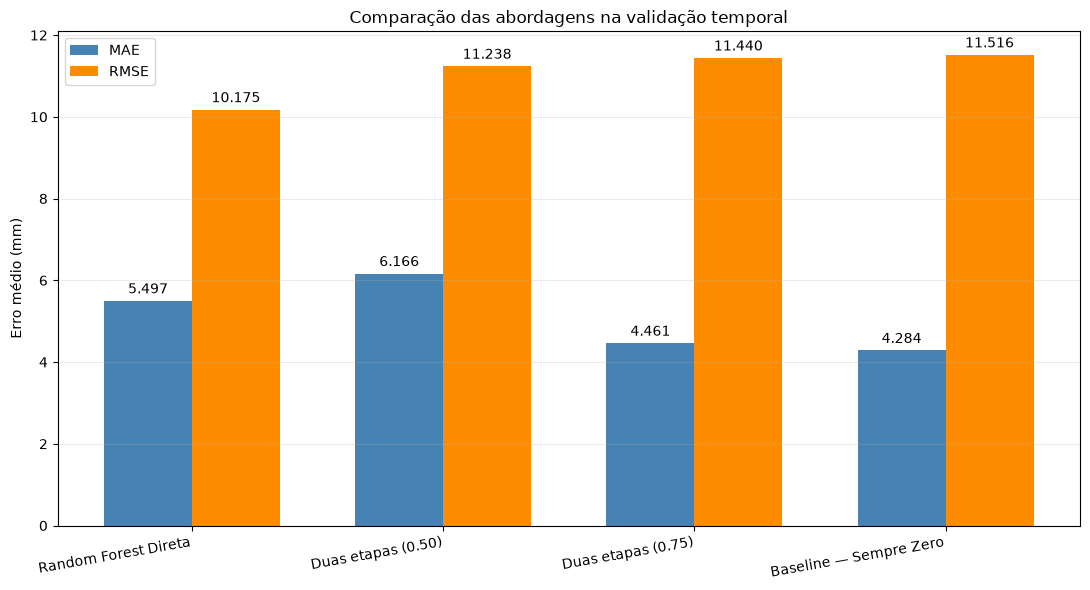

In [12]:
# Seleção das quatro configurações para o gráfico
df_grafico_complementar = df_complementar[
    (
        df_complementar["Modelo"] == "Random Forest Direta"
    )
    |
    (
        df_complementar["Modelo"] == "Baseline — Sempre Zero"
    )
    |
    (
        (df_complementar["Modelo"] == "Random Forest Duas Etapas")
        & (df_complementar["Threshold"].isin([0.50, 0.75]))
    )
].copy()

# Rótulos simplificados
df_grafico_complementar["Abordagem"] = (
    df_grafico_complementar.apply(
        lambda linha: (
            f"Duas etapas ({linha['Threshold']:.2f})"
            if linha["Modelo"] == "Random Forest Duas Etapas"
            else linha["Modelo"]
        ),
        axis=1
    )
)

# Ordenação pelo RMSE
df_grafico_complementar = (
    df_grafico_complementar
    .sort_values("RMSE_mm")
)

# Gráfico
fig, ax = plt.subplots(figsize=(11, 6))

x = np.arange(len(df_grafico_complementar))
largura = 0.35

barras_mae = ax.bar(
    x - largura / 2,
    df_grafico_complementar["MAE_mm"],
    largura,
    label="MAE",
    color="steelblue"
)

barras_rmse = ax.bar(
    x + largura / 2,
    df_grafico_complementar["RMSE_mm"],
    largura,
    label="RMSE",
    color="darkorange"
)

ax.set_xticks(x)
ax.set_xticklabels(
    df_grafico_complementar["Abordagem"],
    rotation=10,
    ha="right"
)

ax.set_ylabel("Erro médio (mm)")
ax.set_title(
    "Comparação das abordagens na validação temporal"
)

ax.bar_label(barras_mae, fmt="%.3f", padding=3)
ax.bar_label(barras_rmse, fmt="%.3f", padding=3)

ax.grid(axis="y", alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()

## 7. Síntese dos resultados e limitações

### 7.1 Principais resultados

O estudo investigou a previsão do acumulado diário de precipitação na estação meteorológica A701 — Mirante de Santana, em São Paulo, utilizando dados do Instituto Nacional de Meteorologia (INMET) referentes ao período de 2010 a 2025.

Os registros horários foram convertidos para o fuso horário `America/Sao_Paulo` antes da agregação diária, respeitando as mudanças históricas do horário de verão. A base consolidada apresentou **5.844 registros diários**, dos quais **5.652 possuíam valores válidos de precipitação**, correspondendo a uma cobertura de aproximadamente **96,71%**.

A análise exploratória revelou uma distribuição assimétrica, com predominância de dias secos ou com baixos acumulados. Aproximadamente **57,84% dos registros válidos apresentaram precipitação igual a zero**, enquanto apenas **1,11% registraram acumulados superiores a 50 mm**.

Foram avaliados modelos de referência, regressão linear, Random Forest e XGBoost, considerando diferentes conjuntos de variáveis temporais e meteorológicas.

Na validação temporal, a **Random Forest multivariada otimizada apresentou o menor MAE médio entre os modelos de regressão direta, com 5,497 mm**, e RMSE médio de **10,175 mm**. O XGBoost otimizado apresentou RMSE ligeiramente inferior, de **10,156 mm**, mas MAE superior, de **5,653 mm**.

Considerando o equilíbrio entre as métricas, especialmente o menor MAE e a proximidade do RMSE em relação ao melhor resultado, a Random Forest multivariada otimizada foi selecionada para avaliação final.

No conjunto de teste, composto por **991 observações**, referentes ao período de **12 de janeiro de 2022 a 21 de dezembro de 2025**, o modelo apresentou **MAE de 5,251 mm** e **RMSE de 9,217 mm**.

### 7.2 Limitações identificadas

A análise dos erros por intensidade demonstrou que o desempenho do modelo varia consideravelmente conforme o volume de precipitação observado.

Em dias sem precipitação, o MAE foi de **2,85 mm**. Entretanto, nos eventos superiores a 20 mm, os erros aumentaram significativamente, chegando a **50,68 mm** nos dias com precipitação superior a 50 mm.

Também foi identificada tendência de superestimação dos baixos acumulados e subestimação dos eventos intensos. Na faixa superior a 50 mm, a precipitação média observada foi de **60,92 mm**, enquanto a média prevista foi de apenas **10,24 mm**.

A baixa frequência desses eventos constitui uma limitação adicional. No conjunto de teste, apenas **10 observações** apresentaram precipitação superior a 50 mm, o que exige cautela na generalização dos resultados.

Essas limitações indicam que o modelo não deve ser interpretado como uma ferramenta suficientemente validada para antecipação de eventos extremos, especialmente em aplicações que dependam da identificação precisa de chuvas intensas.

### 7.3 Experimento complementar

Como investigação adicional, foi desenvolvida uma arquitetura em duas etapas, combinando classificação da ocorrência de precipitação e regressão da intensidade.

A avaliação dos diferentes limiares de classificação demonstrou que o aumento do threshold reduziu o MAE da arquitetura completa, mas também elevou a proporção de dias classificados como sem chuva.

Com threshold de **0,75**, aproximadamente **95,70% dos dias foram classificados como secos**, resultando em MAE médio de **4,461 mm** e RMSE médio de **11,440 mm**.

Por outro lado, o threshold de **0,50 apresentou o menor RMSE da arquitetura em duas etapas, de 11,238 mm**, acompanhado de MAE médio de **6,166 mm**.

O baseline que prevê sempre precipitação igual a zero apresentou **MAE médio de 4,284 mm** e **RMSE médio de 11,516 mm**, reforçando que a minimização isolada do erro absoluto médio pode favorecer estratégias excessivamente conservadoras.

A Random Forest multivariada de regressão direta manteve o menor RMSE entre essas abordagens, com **10,175 mm**, embora determinadas configurações da arquitetura em duas etapas tenham apresentado MAE inferior.

O experimento em duas etapas foi desenvolvido após a avaliação inicial do modelo direto e seus resultados foram analisados exclusivamente por validação temporal no conjunto de treinamento. Dessa forma, constitui uma investigação complementar, e não uma nova avaliação independente no teste final.

### 7.4 Considerações finais

Os resultados demonstram a viabilidade de aplicar técnicas de aprendizado de máquina à estimativa do acumulado diário de precipitação com base em informações meteorológicas históricas.

Entre os modelos avaliados, a **Random Forest multivariada otimizada apresentou desempenho competitivo e foi selecionada como abordagem principal**, considerando o equilíbrio entre as métricas de validação e a capacidade de representar parcialmente a variabilidade dos acumulados diários.

Entretanto, a elevada frequência de dias secos, a baixa representatividade de eventos intensos e a tendência de subestimação dos maiores acumulados constituem limitações importantes.

O experimento complementar em duas etapas não demonstrou vantagem consistente sobre a regressão direta, evidenciando que a separação entre ocorrência e intensidade da chuva, isoladamente, não foi suficiente para superar as limitações identificadas.

Como possibilidades de trabalhos futuros, destacam-se a incorporação de previsões meteorológicas externas, a investigação de modelos probabilísticos, a utilização de funções de perda específicas para eventos intensos e avaliações adicionais em períodos independentes.

Conclui-se que a modelagem desenvolvida representa uma **abordagem exploratória para previsão diária de precipitação**, mas ainda necessita de aperfeiçoamentos para aplicações que dependam da estimativa precisa de chuvas intensas.